# OpenSMILE Feature Extraction

## Available Feature Sets

OpenSMILE Python supports 3 main feature sets:

1. ComParE 2016 (6000+ features)
2. GeMAPS (variants: v01a, v01b) 
3. eGeMAPS (variants: v01a, v01b, v02)

Features can be extracted at different levels:
- Low-Level Descriptors (LLD)
- Functionals  
- LLD deltas (ComParE 2016 only)

## eGeMAPS Features

The extended Geneva Minimalistic Acoustic Parameter Set (eGeMAPS) provides standardized acoustic features for voice analysis. These features are well-suited for:
- Affective computing
- Speech pathology
- Emotion recognition
- Detecting emotional and aggressive speech patterns

Source: [Research Paper](https://ieeexplore.ieee.org/stamp/stamp.jsp?tp=&arnumber=7160715)

## Feature Set Comparison

| Feature Set   | LLD / Deltas / Functionals |
|---------------|---------------------------|
| ComParE_2016  | 65 / 65 / 6373           |
| GeMAPSv01a    | 18 / - / 62              |
| GeMAPSv01b    | 18 / - / 62              |
| eGeMAPSv01a   | 23 / - / 88              |
| eGeMAPSv01b   | 23 / - / 88              |
| eGeMAPSv02    | 25 / - / 88              |

## Example Configuration


# (Optional) - need to (re)extract the features from all video/audio files
## Duration around 80 Minutes

In [ ]:
import opensmile
from pathlib import Path
import speech_feature_extractor.opensmile_extractor as opensmile_extractor

audio_files_path = Path("..") / "data" / "videos"

audio_files = [str(file.resolve()) for file in audio_files_path.glob("*.mp4")]
audio_files.sort()
opensmile_extractor.extract(
    audio_files,
    output_path=Path('data')/"opensmile_egemapsv02.csv",
    opensmile_set=opensmile.FeatureSet.eGeMAPSv02,
    opensmile_feature_level=opensmile.FeatureLevel.Functionals,
)

(Optional) MFCC Features extraction - 20 Feautures around how much time 5 minutes

In [ ]:
import librosa
import pandas as pd
from pathlib import Path


def extract_mfcc(audio_path, n_mfcc=13):
    try:
        y, sr = librosa.load(audio_path, sr=None)
        mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc)
        mfcc_mean = mfccs.mean(axis=1)
        return mfcc_mean
    except Exception as e:
        print(f"Error loading file {audio_path}: {e}")
        return None

audio_files_path = Path("..") / "data" / "videos"
audio_files = [str(file.resolve()) for file in audio_files_path.glob("*.mp4")]
audio_files.sort()

mfcc_features = []
file_names = [] 

for audio_file in audio_files:
    mfcc_mean = extract_mfcc(audio_file)
    if mfcc_mean is not None: 
        mfcc_features.append(mfcc_mean)
        file_names.append(Path(audio_file).name)

mfcc_df = pd.DataFrame(mfcc_features, columns=[f"MFCC_{i+1}" for i in range(13)])
mfcc_df["video_file_name"] = file_names

output_path = Path("data") / "mfcc_features.csv"
mfcc_df.to_csv(output_path, index=False)
print(f"MFCC features saved to {output_path}")

Acoustic and Linguistic features merged

In [2]:
from pathlib import Path
import pandas as pd

egemapsv02_df = pd.read_csv(Path("data") / "opensmile_egemapsv02.csv")
mfcc_df = pd.read_csv(Path("data") / "mfcc_features.csv")
acoustic_df = pd.merge(
    mfcc_df,
    egemapsv02_df,
    on="video_file_name",
    how="inner",
)

acoustic_df = acoustic_df.loc[:, ~acoustic_df.columns.duplicated()]
print(f"Merged Acoustic DataFrame Shape: {acoustic_df.shape}")

pos_features_df = pd.read_csv("data/pos_transcript.csv")
liwc_features_df = pd.read_csv("data/liwc_transcript.csv")
tfidf_ngrams_features_df = pd.read_csv("data/top_50_tfidf_ngram_transcript.csv")

linguistic_df = pd.concat(
    [
        liwc_features_df,
        pos_features_df,
        tfidf_ngrams_features_df,
    ],
    axis=1,
)
linguistic_df = linguistic_df.loc[:, ~linguistic_df.columns.duplicated()]

print(f"Merged Linguistic DataFrame Shape: {linguistic_df.shape}")

linguistic_df = linguistic_df.set_index("video_file_name")
acoustic_df = acoustic_df.set_index("video_file_name")

common_indices = linguistic_df.index.intersection(acoustic_df.index)

initial_linguistic_count = linguistic_df.shape[0]
initial_acoustic_count = acoustic_df.shape[0]

common_indices = linguistic_df.index.intersection(acoustic_df.index)

linguistic_df = linguistic_df.loc[common_indices]
acoustic_df = acoustic_df.loc[common_indices]
removed_linguistic = initial_linguistic_count - linguistic_df.shape[0]
removed_acoustic = initial_acoustic_count - acoustic_df.shape[0]

print(f"Number of files removed from linguistic_df: {removed_linguistic}")
print(f"Number of files removed from acoustic_df: {removed_acoustic}")

assert (
    linguistic_df.shape[0] == acoustic_df.shape[0]
), f"Mismatch in number of rows: linguistic_df has {linguistic_df.shape[0]} rows, acoustic_df has {acoustic_df.shape[0]} rows."

# Calculate and display class distribution
print("\nClass Distribution:")
total_distribution = linguistic_df['label'].value_counts()
print("\nTotal Dataset:")
print(total_distribution)
print(f"Percentage:\n{(total_distribution / len(linguistic_df) * 100).round(2)}%")


Merged Acoustic DataFrame Shape: (1067, 105)
Merged Linguistic DataFrame Shape: (1008, 175)
Number of files removed from linguistic_df: 1
Number of files removed from acoustic_df: 60

Class Distribution:

Total Dataset:
label
Non Hate    592
Hate        415
Name: count, dtype: int64
Percentage:
label
Non Hate    58.79
Hate        41.21
Name: count, dtype: float64%


In [27]:
# Select only numerical columns and preserve the label column
numerical_columns = linguistic_df.select_dtypes(include=["number"]).columns
label_column = "label"

# Calculate statistical summary for all categories (ignoring label)
all_categories_summary = (
    linguistic_df[numerical_columns]
    .agg(["mean", "median", "std", "min", "max"])
    .transpose()
)
all_categories_summary["label"] = "All"

# Add label-specific statistics to the summary
hate_summary = (
    linguistic_df[linguistic_df[label_column] == "Hate"][numerical_columns]
    .agg(["mean", "median", "std", "min", "max"])
    .transpose()
)
hate_summary["label"] = "Hate"

non_hate_summary = (
    linguistic_df[linguistic_df[label_column] == "Non Hate"][numerical_columns]
    .agg(["mean", "median", "std", "min", "max"])
    .transpose()
)
non_hate_summary["label"] = "Non Hate"

# Combine all summaries into one dataframe
combined_summary = pd.concat([all_categories_summary, hate_summary, non_hate_summary])

# Reset index and arrange the summary for display
combined_summary.reset_index(inplace=True)
combined_summary.rename(columns={"index": "feature"}, inplace=True)
combined_summary.to_csv("data/linguistic_stats.csv")

Splitting the Dataset

The following line of code splits the dataset into training and testing sets. 

- **X_train, X_test**: These variables hold the functional features for the training and testing sets, respectively.
- **y_train, y_test**: These variables hold the corresponding labels (hate/non-hate) for the training and testing sets.

The `train_test_split()` function from `sklearn` is used for this purpose. It takes the following parameters:
- **functional_features**: The acoustic features extracted using OpenSmile (eGeMAPS) from the dataset.
- **labels**: Corresponding labels for hate speech classification (0 for non-hate and 1 for hate speech).
- **test_size=0.3**: 30% of the data is allocated for the testing set, and 70% for the training set.
- **random_state=42**: Ensures reproducibility by setting a fixed seed for random operations.


Models

- Random Forest: For its ability to handle a large number of features and its robustness in dealing with different types of acoustic data.
- Support Vector Machines (SVM): Suitable for detecting subtle differences in speech patterns.
- Gradient Boosting: Used for its high performance in multi-feature classification tasks.

Key evaluation metrics overview

- Accuracy: Use when classes are balanced, or when the overall correctness of predictions matters.
- Precision: Important when false positives are costly (e.g., wrongly labeling something as hate speech).
- Recall: Important when false negatives are costly (e.g., failing to identify hate speech).
- F1-Score: Use when you need to balance precision and recall, especially with imbalanced datasets.
- AUC: Use to evaluate how well your model distinguishes between classes, especially when considering different classification thresholds.


Overall class distribution:
bool_label
0    58.79%
1    41.21%
Name: proportion, dtype: object
Training Gradient Boosting with cross-validation...

Cross-validation results for Gradient Boosting:
Training Random Forest with cross-validation...

Cross-validation results for Random Forest:
Training Support Vector Machine with cross-validation...

Cross-validation results for Support Vector Machine:
Training Naive Bayes with cross-validation...

Cross-validation results for Naive Bayes:
Training Logistic Regression with cross-validation...

Cross-validation results for Logistic Regression:
Training Decision Tree with cross-validation...

Cross-validation results for Decision Tree:
Training Neural Network with cross-validation...

Cross-validation results for Neural Network:
Training Ensemble with cross-validation...

Cross-validation results for Ensemble:

Cross-validation results on training data:
Model                     CV Accuracy    CV Precision    CV Recall    CV F1-Score    CV AU

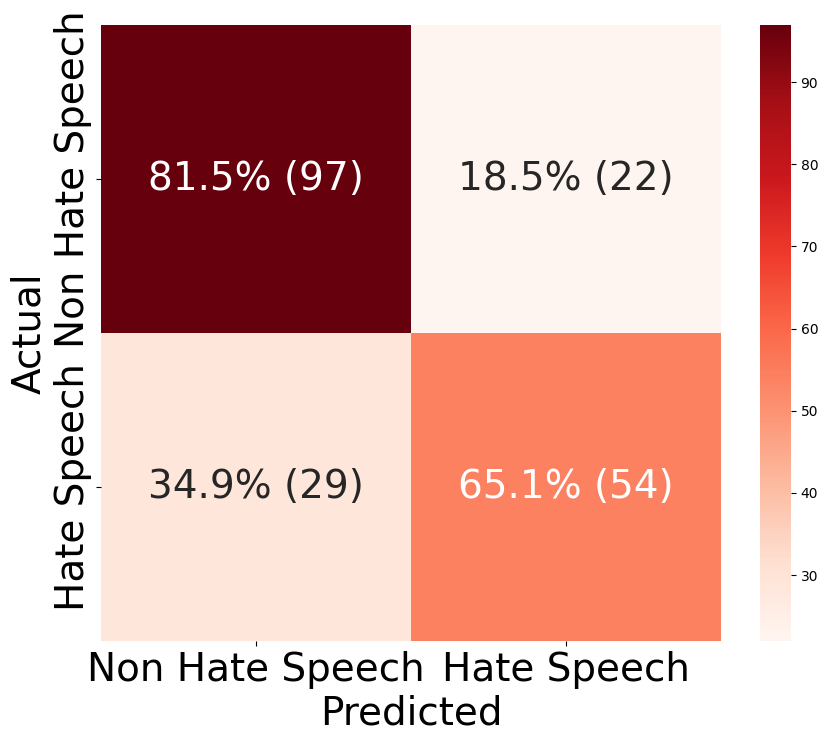

Model saved: models/acoustic_ensemble_features_101.pkl


PosixPath('models/acoustic_ensemble_features_101.pkl')

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from tabulate import tabulate
import pickle
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report
from utils.audio import train_logistic_regression, train_random_forest, train_gradient_boosting, train_naive_bayes, train_decision_tree, train_neural_network, train_svm, train_ensemble

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

from utils.audio import prepare_acoustic_data


def evaluate_model_cv(model, X, y, model_name, cv=5):
    # Perform cross-validation
    cv_accuracy = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    cv_precision = cross_val_score(model, X, y, cv=cv, scoring='precision')
    cv_recall = cross_val_score(model, X, y, cv=cv, scoring='recall')
    cv_f1 = cross_val_score(model, X, y, cv=cv, scoring='f1')
    cv_auc = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')

    # Return mean scores
    return [
        model_name,
        cv_accuracy.mean(),
        cv_precision.mean(),
        cv_recall.mean(),
        cv_f1.mean(),
        cv_auc.mean(),
        # X.shape[1],
    ]


def save_model(
    model, model_name, num_features, feature_names, X, y, scaler, labels
):
    model.scaler = scaler
    model.feature_names = feature_names
    
    filename = (
        f"acoustic_{model_name.lower().replace(' ', '_')}_features_{num_features}.pkl"
    )
    filepath = models_dir / filename
    with open(filepath, "wb") as file:
        pickle.dump(model, file)

    print(f"Model saved: {filepath}")
    return filepath


def main(merged_df):
    X, y, feature_names, scaler, X_raw = prepare_acoustic_data(merged_df)

    # Split data into train and test sets first
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    # Display class distribution
    print("\nOverall class distribution:")
    print(pd.Series(y).value_counts(normalize=True).mul(100).round(2).astype(str) + '%')

    results = []
    classifiers = {
        "Gradient Boosting": train_gradient_boosting,
        "Random Forest": train_random_forest,
        "Support Vector Machine": train_svm,
        "Naive Bayes": train_naive_bayes,
        "Logistic Regression": train_logistic_regression,
        "Decision Tree": train_decision_tree,
        "Neural Network": train_neural_network,
        "Ensemble": train_ensemble,
    }

    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    for model_name, train_func in classifiers.items():
        print(f"Training {model_name} with cross-validation...")
        model = train_func(X_train, y_train)  # Initialize model
        results.append(evaluate_model_cv(model, X, y, model_name, cv=skf))

        # print(f"\nCross-validation results for {model_name}:")
        # cv_scores = cross_val_score(
        #     model, X, y, cv=skf
        # ) 

    results.sort(key=lambda x: x[1], reverse=True)

    headers = [
        "Model",
        "CV Accuracy",
        "CV Precision",
        "CV Recall",
        "CV F1-Score",
        "CV AUC",
    ]

    print("\nCross-validation results on training data:")
    print(tabulate(results, headers=headers, floatfmt=".2f"))

    best_model_name, *_ = results[0]
    print(f"\nBest Model (based on CV accuracy): {best_model_name}")

    # Train best model on full training set
    best_model = classifiers[best_model_name](X_train, y_train)

    # Evaluate on test set
    y_pred = best_model.predict(X_test)
    print("\nTest Set Performance:")
    print(classification_report(y_test, y_pred))

    # Create confusion matrix for test set predictions
    cm = confusion_matrix(y_test, y_pred)
    cm_percentage = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100

    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm_percentage[i, j]:.1f}% ({cm[i, j]})"

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Reds",
        xticklabels=["Non Hate Speech", "Hate Speech"],
        yticklabels=["Non Hate Speech", "Hate Speech"],
        annot_kws={"size": 28},
    )
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.ylabel("Actual", fontsize=28)
    plt.xlabel("Predicted", fontsize=28)
    plt.show()

    file_path = save_model(
        best_model, best_model_name, X.shape[1], feature_names, X_raw, y, scaler, merged_df["label"]
    )

    return file_path


if __name__ == "__main__":
    best_acoustic_model_file_path = main(acoustic_df)
best_acoustic_model_file_path

Linguistic Features

#What the Feature Set Represents

The linguistic feature set extracted from transcripts captures both structural and semantic aspects of the text. The two main types of features are:

- Part-of-Speech (POS) Tags: These features represent the grammatical structure of the text, identifying the roles of individual words (nouns, verbs, adjectives, etc.). POS tags offer insights into how sentences are constructed and what kinds of words dominate the text.
- LIWC Features: These are derived from the Linguistic Inquiry and Word Count (LIWC) dictionary, which categorizes words into psychological and social dimensions. Examples include emotional tone, cognitive processes, and social references. LIWC features provide an understanding of the emotional and psychological content within the text.
#Why We Use This Feature Set

This feature set is used to gain insights into both the linguistic and psychological aspects of the transcript content. By extracting POS tags, we can analyze sentence structure, word choice, and patterns that may indicate complexity, formality, or intent. LIWC features, on the other hand, help reveal deeper psychological or social elements, such as the presence of emotional language, cognitive reasoning, or references to social dynamics.

This combination of features is especially useful for tasks like sentiment analysis, hate speech detection, and psychological profiling from text data.

#Extraction Process

The extraction process is straightforward:

- POS Tags: Extracted using the pos_tag_transcripts function, which processes transcripts using the spaCy model and replaces them with sequences of POS tags.
- LIWC Features: Extracted using the LIWCExtractor class. This function matches words in the transcript to predefined LIWC categories and counts their occurrences.
#Normalization Process

Normalization ensures that the extracted features are comparable across different texts:

- Text Normalization: Handled by the normalize_transcripts function in the LIWCExtractor class, which standardizes the text by removing inconsistencies.
- Feature Normalization: LIWC feature counts are normalized by dividing them by the total word count to ensure relative values are extracted, making comparisons across texts more meaningful.

Read TXT to CSV

In [4]:
from pathlib import Path
import pandas as pd
from pandas import DataFrame

current_script_path = Path().resolve()
transcript_folder = current_script_path.parent / "data" / "transcript"

data = []

for file in transcript_folder.rglob("*.txt"):
    with open(file, "r") as transcript_obj:
        transcript_content = transcript_obj.read()
        data.append({"file_name": file.name, "transcript": transcript_content})

transcript_df: DataFrame = pd.DataFrame(data)

transcript_hatemm = current_script_path.parent / "data" / "transcript_hatemm.csv"
transcript_df.to_csv(transcript_hatemm, index=False)

print(f"Processed {len(transcript_df)} transcripts and saved them to {transcript_hatemm}")

Processed 1066 transcripts and saved them to /share/documents/students/pablo2/data/transcript_hatemm.csv


In [81]:
from pathlib import Path
import pandas as pd

current_script_path = Path().resolve()
transcript_hatemm = current_script_path.parent / "data" / "transcript_hatemm.csv"
annotations_file = current_script_path / "data" / "hatemm_annotation.csv"

transcript_df = pd.read_csv(transcript_hatemm)
annotation_df = pd.read_csv(annotations_file)
transcript_df['file_key'] = transcript_df['file_name'].str.split('.', n=1).str[0]
annotation_df['file_key'] = annotation_df['video_file_name'].str.split('.', n=1).str[0]

merged_df = pd.merge(transcript_df, annotation_df, on='file_key', how='inner')

transcript_count = len(transcript_df)
annotation_count = len(annotation_df)
merged_count = len(merged_df)

print(f"Number of transcripts: {transcript_count}")
print(f"Number of annotations: {annotation_count}")
print(f"Number of merged entries: {merged_count}")

assert merged_count > 0, "No matching entries were found between transcripts and annotations."
print("Merged DataFrame created successfully.")
print(merged_df.columns)

Number of transcripts: 907
Number of annotations: 1083
Number of merged entries: 907
Merged DataFrame created successfully.
Index(['file_name', 'transcript', 'file_key', 'video_file_name', 'label',
       'hate_snippet', 'target'],
      dtype='object')


In [83]:
def check_model_feature_compatibility(model_path, sample_features):
    """
    Check if a pickle file containing a linguistic model is compatible with extracted features.

    Parameters:
    - model_path (str): Path to the pickle file containing the linguistic model.
    - sample_features (dict): A sample dictionary of extracted features.

    Returns:
    - bool: True if compatible, False otherwise.
    - list: List of missing features, if any.
    """
    try:
        with open(model_path, 'rb') as file:
            model = pickle.load(file)

        model_features = getattr(model, 'feature_names_in_', None)
        if model_features is None:
            raise ValueError("The model does not have feature names information.")

        sample_feature_set = set(sample_features.keys())
        model_feature_set = set(model_features)
        missing_features = list(model_feature_set - sample_feature_set)

        return len(missing_features) == 0, missing_features
    except Exception as e:
        print(f"Error checking model compatibility: {str(e)}")
        return False, []

Features extraction funciton definition

In [1]:
import spacy
import numpy as np

def load_model(language):
    """
    Load the spaCy model and set it to use GPU if available.
    """
    model_names = {
        'english': 'en_core_web_trf',
        'german': 'de_dep_news_trf',
        'polish': 'pl_core_news_lg'
    }
    if language.lower() not in model_names:
        raise ValueError(f"Unsupported language '{language}'. Supported languages are: {list(model_names.keys())}")
    print("Loading SpaCy model...")
    nlp = spacy.load(model_names[language.lower()])
    print(f"Using SpaCy pipeline: {nlp.pipe_names}")
    return nlp

def extract_pos_features(text, nlp_model):
    """
    Extract POS features using a SpaCy model, matching the functionality of the second function.
    """
    doc = nlp_model(text)
    pos_tags = list(nlp_model.get_pipe("tagger").labels)
    total_tokens = len(doc)
    tag_counts = {tag: 0 for tag in pos_tags}
    for token in doc:
        if token.tag_ in tag_counts:
            tag_counts[token.tag_] += 1
    pos_freqs = {
        f"POS_{tag}": count / total_tokens if total_tokens > 0 else 0
        for tag, count in tag_counts.items()
    }
    return pos_freqs

merged_df = transcript_df + annotation_df + features_set1 + ....

POS Features

In [2]:
import string
import pandas as pd

transcript_annotation = pd.read_csv("data/hatemm_transcripts_annotation_en.csv")

transcript_annotation.dropna(subset=['transcript'], inplace=True)

lowercase = True
remove_punctuation = True

def normalize_transcript(transcript):
    if lowercase:
        transcript = transcript.lower()
    if remove_punctuation:
        transcript = transcript.translate(str.maketrans('', '', string.punctuation))
    return transcript

transcript_annotation['normalized_transcript'] = transcript_annotation['transcript'].apply(normalize_transcript)

transcript_annotation.to_csv("data/hatemm_transcripts_normalized.csv", index=False)

(Optional) - need to (re)extract the features from all transcript
#Duration around 5 Minutes

In [3]:
import pandas as pd
transcript_annotation = pd.read_csv("data/hatemm_transcripts_normalized.csv")
nlp = load_model('english')
texts = transcript_annotation['normalized_transcript'].fillna("").astype(str).tolist()
pos_features = [extract_pos_features(text, nlp) for text in texts]
pos_features_df = pd.DataFrame(pos_features)
merged_df = pd.concat([transcript_annotation, pos_features_df], axis=1)
merged_df.to_csv("data/pos_transcript.csv",index=False)

original_columns = merged_df.columns[: -len(pos_features_df.columns)]
new_columns = pos_features_df.columns
total_features_added = len(new_columns)

print(f"Summary:")
print(f"- Total features added: {total_features_added}")
print(f"- New columns added: {list(new_columns)}")
print(f"- Total columns after addition: {len(merged_df.columns)}")

Loading SpaCy model...


/Users/pablofreitas/git_ws/HateScan/.venv/lib/python3.11/site-packages/thinc/shims/pytorch.py:261: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.

Using SpaCy pipeline: ['transformer', 'tagger', 'parser', 'attribute_ruler', 'lemmatizer', 'ner']
Summary:
- Total features added: 49
- New columns added: ['POS_$', "POS_''", 'POS_,', 'POS_-LRB-', 'POS_-RRB-', 'POS_.', 'POS_:', 'POS_ADD', 'POS_AFX', 'POS_CC', 'POS_CD', 'POS_DT', 'POS_EX', 'POS_FW', 'POS_HYPH', 'POS_IN', 'POS_JJ', 'POS_JJR', 'POS_JJS', 'POS_LS', 'POS_MD', 'POS_NFP', 'POS_NN', 'POS_NNP', 'POS_NNPS', 'POS_NNS', 'POS_PDT', 'POS_POS', 'POS_PRP', 'POS_PRP$', 'POS_RB', 'POS_RBR', 'POS_RBS', 'POS_RP', 'POS_SYM', 'POS_TO', 'POS_UH', 'POS_VB', 'POS_VBD', 'POS_VBG', 'POS_VBN', 'POS_VBP', 'POS_VBZ', 'POS_WDT', 'POS_WP', 'POS_WP$', 'POS_WRB', 'POS_XX', 'POS_``']
- Total columns after addition: 59


(Optional) - need to (re)extract the features from all transcript
#Duration around 5 Minutes

In [ ]:
from speech_feature_extractor.liwc_extractor import LIWCExtractor
from pathlib import Path

language = "English"
liwc_path = Path.cwd() / "csl-speech-feature-extractor" / "speech_feature_extractor" / "data" / f"LIWC_{language}.dic"
liwc_extractor = LIWCExtractor(liwc_path)

transcript_annotation = pd.read_csv("data/hatemm_transcripts_normalized.csv")
texts = transcript_annotation["normalized_transcript"].fillna("").astype(str).tolist()

liwc_features = [liwc_extractor.extract_from_transcript(text) for text in texts]
liwc_features_df = pd.DataFrame(liwc_features, columns=liwc_extractor.get_category_names())


merged_df = pd.concat([transcript_annotation, liwc_features_df], axis=1)
merged_df.to_csv("data/liwc_transcript.csv",index=False)

original_columns = merged_df.columns[:-len(liwc_features_df.columns)]
new_columns = liwc_features_df.columns
total_features_added = len(new_columns)

print(f"Summary:")
print(f"- Total features added: {total_features_added}")
print(f"- New columns added: {list(new_columns)}")
print(f"- Total columns after addition: {len(merged_df.columns)}")

Summary:
- Total features added: 69
- New columns added: ['funct', 'pronoun', 'ppron', 'i', 'we', 'you', 'shehe', 'they', 'ipron', 'article', 'verb', 'auxverb', 'past', 'present', 'future', 'adverb', 'preps', 'conj', 'negate', 'quant', 'number', 'swear', 'social', 'family', 'friend', 'humans', 'affect', 'posemo', 'negemo', 'anx', 'anger', 'sad', 'cogmech', 'insight', 'cause', 'discrep', 'tentat', 'certain', 'inhib', 'incl', 'excl', 'percept', 'see', 'hear', 'feel', 'bio', 'body', 'health', 'sexual', 'ingest', 'relativ', 'motion', 'space', 'time', 'work', 'achieve', 'leisure', 'home', 'money', 'relig', 'death', 'assent', 'nonfl', 'filler', 'total_words', 'six_letter_words', 'dict_words', 'punctuation', 'emoticons']
- Total columns after addition: 79


In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
import pickle

transcript_annotation = pd.read_csv("data/hatemm_transcripts_normalized.csv")

texts = transcript_annotation["normalized_transcript"].fillna("").astype(str).tolist()

vectorizer = TfidfVectorizer(
    ngram_range=(1, 3),
    min_df=5,
    max_df=0.7,
    use_idf=True,
    norm="l2"
)

tfidf_features = vectorizer.fit_transform(texts)

term_feature_names = vectorizer.get_feature_names_out()

tfidf_df = pd.DataFrame(tfidf_features.toarray(), columns=term_feature_names)

idf_values = vectorizer.idf_
idf_df = pd.DataFrame({"Term": term_feature_names, "IDF": idf_values}).sort_values(
    by="IDF", ascending=False
)

tfidf_sums = tfidf_df.sum(axis=0).sort_values(ascending=False)
top_50_features = tfidf_sums.head(50).index
top_50_df = tfidf_df[top_50_features]

merged_df = pd.concat([transcript_annotation, top_50_df], axis=1)

merged_df.to_csv("data/top_50_tfidf_ngram_transcript.csv", index=False)
idf_df.to_csv("data/idf_values.csv", index=False)

with open("models/tfidf_vectorizer.pkl", "wb") as vec_file:
    pickle.dump(vectorizer, vec_file)

with open("models/tfidf_top_50_features.pkl", "wb") as features_file:
    pickle.dump(top_50_features.tolist(), features_file)

print("Summary:")
print(f"- Total n-gram features extracted: {len(term_feature_names)}")
print(f"- Top 50 features: {list(top_50_features)}")
print(f"- Total columns after addition: {len(merged_df.columns)}")
print("\nIDF values for the top 10 terms:")
print(idf_df.head(10))

print(top_50_features)

Summary:
- Total n-gram features extracted: 11206
- Top 50 features: ['to', 'and', 'of', 'in', 'that', 'nigger', 'is', 'it', 'oh', 'for', 'this', 'im', 'my', 'we', 'on', 'me', 'he', 'they', 'are', 'your', 'was', 'what', 'be', 'dont', 'know', 'like', 'its', 'not', 'so', 'all', 'no', 'with', 'have', 'up', 'but', 'get', 'youre', 'fucking', 'out', 'just', 'do', 'white', 'fuck', 'people', 'about', 'in the', 'go', 'if', 'yeah', 'were']
- Total columns after addition: 60

IDF values for the top 10 terms:
                 Term       IDF
4701   killing niggas  6.124956
10276     what people  6.124956
4619        just look  6.124956
4620     just look at  6.124956
4629         just see  6.124956
4630        just shit  6.124956
4632      just so you  6.124956
4633        just some  6.124956
4634        just stop  6.124956
4635        just take  6.124956
Index(['to', 'and', 'of', 'in', 'that', 'nigger', 'is', 'it', 'oh', 'for',
       'this', 'im', 'my', 'we', 'on', 'me', 'he', 'they', 'are', 'you

Model training


Percentage Distribution:
label
Non Hate    58.788481
Hate        41.211519
Name: proportion, dtype: float64
Training Gradient Boosting with cross-validation...
Training Random Forest with cross-validation...
Training Support Vector Machine with cross-validation...
Training Naive Bayes with cross-validation...
Training Logistic Regression with cross-validation...
Training Decision Tree with cross-validation...
Training Neural Network with cross-validation...
Training Ensemble with cross-validation...

Cross-validation results on training data:
Model                     CV Accuracy    CV Precision    CV Recall    CV F1-Score    CV AUC
----------------------  -------------  --------------  -----------  -------------  --------
Random Forest                    0.78            0.79         0.62           0.69      0.83
Ensemble                         0.77            0.76         0.64           0.70      0.84
Gradient Boosting                0.76            0.75         0.64           0.69 

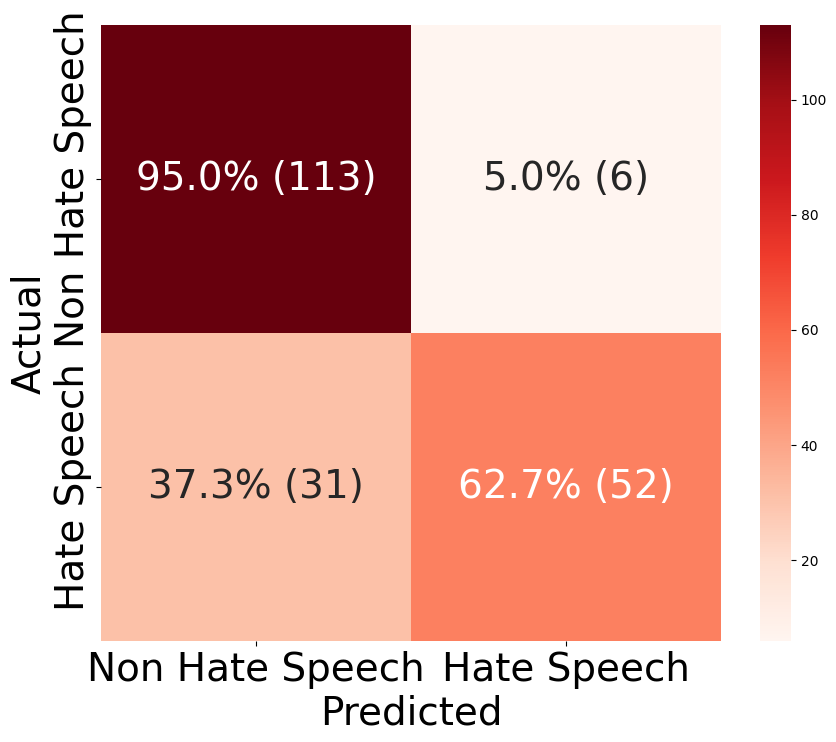


Best Model: Random Forest
Model saved: models/linguistic_random_forest_features_166.pkl


In [3]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from tabulate import tabulate
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import pickle
from pathlib import Path
from sklearn.metrics import classification_report
from sklearn.svm import SVC
import numpy as np

from utils.audio import train_logistic_regression, train_random_forest, train_gradient_boosting, train_naive_bayes, train_decision_tree, train_neural_network, train_svm, train_ensemble

def prepare_linguistic_data(merged_df):
    label_mapping = {'Hate': 1, 'Non Hate': 0}
    merged_df['bool_label'] = merged_df['label'].map(label_mapping)

    print("\nPercentage Distribution:")
    print(merged_df['label'].value_counts(normalize=True) * 100)

    columns_to_drop = [
        "label",
        "bool_label", 
        "Unnamed: 0",
        "file_name",
        "file_key",
        "video_file_name",
        "hate_snippet",
        "target",
        "transcript",
        "language",
        "normalized_transcript",
    ]

    feature_columns = merged_df.columns.difference(columns_to_drop)
    X = merged_df[feature_columns].values
    y = merged_df['bool_label'].values
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_scaled_df = pd.DataFrame(X_scaled, columns=feature_columns)

    feature_names = feature_columns.tolist()

    return X_scaled_df, y, feature_names, scaler, X

def evaluate_model_cv(model, X_train, y_train, model_name, cv=5):
    cv_accuracy = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_precision = cross_val_score(model, X_train, y_train, cv=cv, scoring='precision')
    cv_recall = cross_val_score(model, X_train, y_train, cv=cv, scoring='recall')
    cv_f1 = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    cv_auc = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc') if hasattr(model, "predict_proba") else np.array([0.5]*cv)
    
    return [
        model_name,
        cv_accuracy.mean(),
        cv_precision.mean(),
        cv_recall.mean(),
        cv_f1.mean(),
        cv_auc.mean(),
        # X_train.shape[1]
    ]

models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

def save_model(
    model, model_name, num_features, feature_names, X, y, scaler, labels
):
    model.scaler = scaler
    model.feature_names = feature_names

    filename = (
        f"linguistic_{model_name.lower().replace(' ', '_')}_features_{num_features}.pkl"
    )
    filepath = models_dir / filename
    with open(filepath, "wb") as file:
        pickle.dump(model, file)
    print(f"Model saved: {filepath}")
    return filepath

def main(merged_df):
    X_scaled_df, y, feature_names, scaler, X = prepare_linguistic_data(merged_df)

    # Split data into train and test sets first
    X_train, X_test, y_train, y_test = train_test_split(X_scaled_df, y, test_size=0.2, random_state=42, stratify=y)

    results = []
    classifiers = {
        "Gradient Boosting": train_gradient_boosting,
        "Random Forest": train_random_forest,
        "Support Vector Machine": train_svm,
        "Naive Bayes": train_naive_bayes,
        "Logistic Regression": train_logistic_regression,
        "Decision Tree": train_decision_tree,
        "Neural Network": train_neural_network,
        "Ensemble": train_ensemble,
    }

    # Create stratified k-fold cross validator for training data only
    skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    for model_name, train_func in classifiers.items():
        print(f"Training {model_name} with cross-validation...")
        model = train_func(X_train, y_train)  # Initialize model
        results.append(evaluate_model_cv(model, X, y, model_name, cv=skf))

    results.sort(key=lambda x: x[1], reverse=True)

    headers = [
        "Model",
        "CV Accuracy",
        "CV Precision",
        "CV Recall",
        "CV F1-Score",
        "CV AUC",
        "Num Features",
    ]

    print("\nCross-validation results on training data:")
    print(tabulate(results, headers=headers, floatfmt=".2f"))
    best_model_name, *_ = results[0]
    print(f"\nBest Model (based on CV accuracy): {best_model_name}")

    # Train best model on full training set
    best_model = classifiers[best_model_name](X_train, y_train)

    # Plot confusion matrix for the best model on test set
    y_pred = best_model.predict(X_test)  # Predict on test set
    cm = confusion_matrix(y_test, y_pred)  # Confusion matrix on test set
    cm_percentage = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            annot[i, j] = f"{cm_percentage[i, j]:.1f}% ({cm[i, j]})"

    plt.figure(figsize=(10, 8))
    sns.heatmap(
        cm,
        annot=annot,
        fmt="",
        cmap="Reds",
        xticklabels=["Non Hate Speech", "Hate Speech"],
        yticklabels=["Non Hate Speech", "Hate Speech"],
        annot_kws={"size": 28},
    )
    plt.xticks(fontsize=28)
    plt.yticks(fontsize=28)
    plt.ylabel("Actual", fontsize=28)
    plt.xlabel("Predicted", fontsize=28)
    plt.show()

    results.sort(key=lambda x: x[1], reverse=True)

    headers = [
        "Model",
        "CV Accuracy",
        "CV Precision",
        "CV Recall",
        "CV F1-Score",
        "CV AUC",
    ]

    print(f"\nBest Model: {best_model_name}")
    file_path = save_model(
        best_model,
        best_model_name,
        X.shape[1],
        feature_names,
        X,
        y,
        scaler,
        merged_df["label"],
    )

    return file_path

if __name__ == "__main__":
    best_linguistic_model_file_path = main(linguistic_df)


Percentage Distribution:
label
Non Hate    58.788481
Hate        41.211519
Name: proportion, dtype: float64

Multimodal Ensemble Results (Soft Voting):


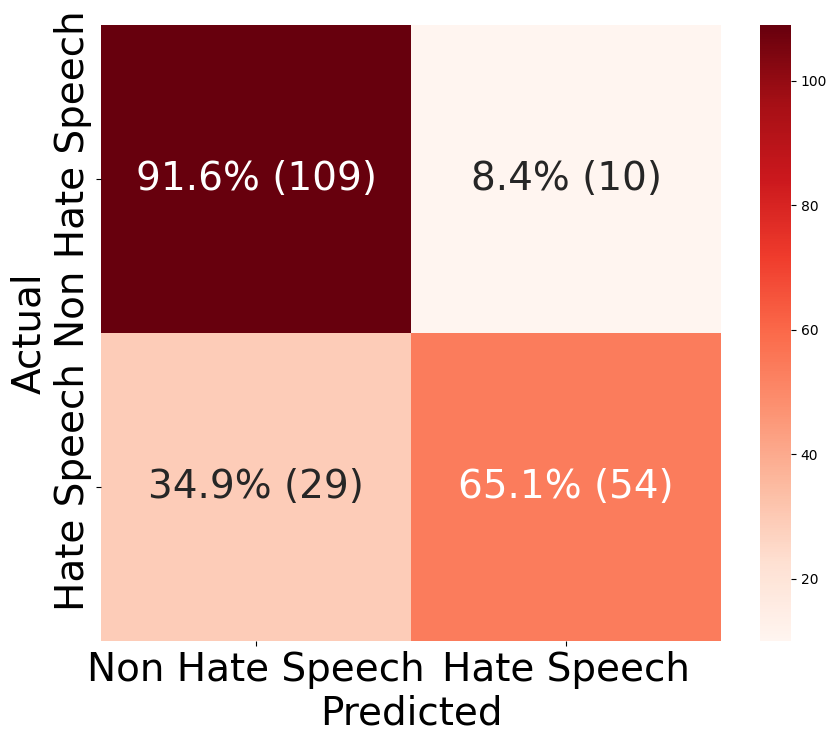

Accuracy: 0.81
Precision: 0.84
Recall: 0.65
F1 Score: 0.73
ROC-AUC Score: 0.90

Classification Report:
                 precision    recall  f1-score   support

Non Hate Speech       0.79      0.92      0.85       119
    Hate Speech       0.84      0.65      0.73        83

       accuracy                           0.81       202
      macro avg       0.82      0.78      0.79       202
   weighted avg       0.81      0.81      0.80       202



In [6]:
import numpy as np
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
)
import seaborn as sns
import matplotlib.pyplot as plt
from utils.audio import prepare_acoustic_data, prepare_linguistic_data
from sklearn.model_selection import train_test_split
import pickle

X_acoustic_scaled, ya, feature_names_acoustic, scaler_acoustic, X_raw_acoustic = (
    prepare_acoustic_data(acoustic_df)
)

# Split data into train and test sets
X_acoustic_train, X_acoustic_test, y_acoustic_train, y_acoustic_test = train_test_split(
    X_acoustic_scaled, ya, test_size=0.2, random_state=42, stratify=ya
)

(
    X_linguistic_scaled,
    yl,
    feature_names_lingusitic,
    scaler_linguistic,
    X_raw_linguistic,
) = prepare_linguistic_data(linguistic_df)

# Split data into train and test sets
X_linguistic_train, X_linguistic_test, y_linguistic_train, y_linguistic_test = (
    train_test_split(
        X_linguistic_scaled, yl, test_size=0.2, random_state=42, stratify=yl
    )
)

with open(f"{best_linguistic_model_file_path}", "rb") as file:
    linguistic_ensemble = pickle.load(file)

with open(f"{best_acoustic_model_file_path}", "rb") as file:
    acoustic_ensemble = pickle.load(file)

# Get probability predictions
acoustic_test_probs = acoustic_ensemble.predict_proba(X_acoustic_test)
linguistic_test_probs = linguistic_ensemble.predict_proba(X_linguistic_test)

# Combine predictions for soft voting
combined_test_probs = (acoustic_test_probs + linguistic_test_probs) / 2
multimodal_test_preds = np.argmax(combined_test_probs, axis=1)

# Evaluate the ensemble
print("\nMultimodal Ensemble Results (Soft Voting):")

# Confusion Matrix
cm = confusion_matrix(y_acoustic_test, multimodal_test_preds)
cm_percentage = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis] * 100
annot = np.empty_like(cm).astype(str)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        annot[i, j] = f"{cm_percentage[i, j]:.1f}% ({cm[i, j]})"

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=annot,
    fmt="",
    cmap="Reds",
    xticklabels=["Non Hate Speech", "Hate Speech"],
    yticklabels=["Non Hate Speech", "Hate Speech"],
    annot_kws={"size": 28},
)
plt.xticks(fontsize=28)  # Change 14 to your desired font size
plt.yticks(fontsize=28)
plt.ylabel("Actual", fontsize=28)
plt.xlabel("Predicted", fontsize=28)
plt.show()

# Calculate evaluation metrics
accuracy = accuracy_score(y_acoustic_test, multimodal_test_preds)
precision = precision_score(y_acoustic_test, multimodal_test_preds)
recall = recall_score(y_acoustic_test, multimodal_test_preds)
f1 = f1_score(y_acoustic_test, multimodal_test_preds)

roc_auc = roc_auc_score(y_acoustic_test, combined_test_probs[:, 1])

# Print evaluation metrics
print(f"Accuracy: {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print(f"ROC-AUC Score: {roc_auc:.2f}")

# Detailed classification report
print("\nClassification Report:")
print(
    classification_report(
        y_acoustic_test,
        multimodal_test_preds,
        target_names=["Non Hate Speech", "Hate Speech"],
    )
)